# Wyszukiwarka – Latent Semantic Indexing (LSI/SVD)

**MOwNiT Lab 6**  
**Autor:** Adam Gawęda

---

## 1. Cel projektu

Projekt polega na implementacji wyszukiwarki tekstowej z zastosowaniem
**Latent Semantic Indexing (LSI)** – techniki opartej na rozkładzie
Singular Value Decomposition macierzy term-dokument.

Porównujemy dwa podejścia:
- **TF-IDF + cosinus** – klasyczne wyszukiwanie wektorowe,
- **LSI (TF-IDF + SVD + cosinus)** – wyszukiwanie w zredukowanej
  przestrzeni pojęć (latent concept space).

Dodatkowym elementem jest implementacja **BM25** jako alternatywnego
schematu ważenia terminów.

Dane: artykuły z Simple English Wikipedia zindeksowane przez web crawler.

## 2. Struktura projektu

```
Wyszukiwarka/
├── src/
│   ├── preprocessing.py   # build_index(), compute_tf_matrix(), apply_idf(), apply_bm25()
│   ├── svd.py             # truncated_svd() → SVDComponents(U, sigma, Vt, k)
│   ├── search.py          # cosine_search(), lsi_search(), vectorize_query()
│   ├── setup.py           # IndexManager – cache słownika, macierzy, SVD
│   └── crawler/
│       ├── crawler.py     # Web crawler (Simple English Wiki)
│       └── database.py    # SQLite – przechowywanie artykułów
├── client/                # Interfejs webowy (HTML/CSS/JS)
├── app.py                 # Flask REST API
├── main.py                # Interaktywna wyszukiwarka konsolowa
└── LatentSemanticIndexing.py  # Demonstracja LSI na małym przykładzie
```

## 3. Importy i konfiguracja

In [12]:
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sklearn.preprocessing import normalize as sk_normalize

from src.preprocessing import apply_idf, apply_bm25
from src.search import cosine_search, lsi_search
from src.setup import IndexManager
from src.svd import truncated_svd

DB_PATH = './data/simplified_wiki_index.db'

plt.style.use('dark_background')
ACCENT = '#6c63ff'
GREEN  = '#22d3a0'

print('Importy OK')

Importy OK


## 4. Ładowanie / budowa indeksu

In [13]:
mgr = IndexManager()

# --- słownik ---
t0 = time.perf_counter()
index = mgr.load_index()
t_vocab = time.perf_counter() - t0
print(f'Słownik: {len(index):,} terminów  ({t_vocab:.2f}s)')

# --- macierz TF + IDF + normalizacja ---
t0 = time.perf_counter()
doc_matrix, doc_ids = mgr.load_matrix()
t_matrix = time.perf_counter() - t0
print(f'Macierz TF-IDF: {doc_matrix.shape}  ({t_matrix:.2f}s)')
print(f'Liczba dokumentów: {len(doc_ids):,}')

Wczytywanie słownika z pliku cache...
  Słownik: 12,533 terminów
Słownik: 12,533 terminów  (0.01s)
Wczytywanie macierzy term-dokument z pliku cache...
Stosowanie wag IDF...
  IDF [0.02s]
Normalizacja macierzy...


  Normalizacja [0.13s]
Macierz TF-IDF: (12533, 10462)  (0.20s)
Liczba dokumentów: 10,462


## 5. Analiza eksploracyjna

### 5.1. Rozkład częstości terminów (Zipf)

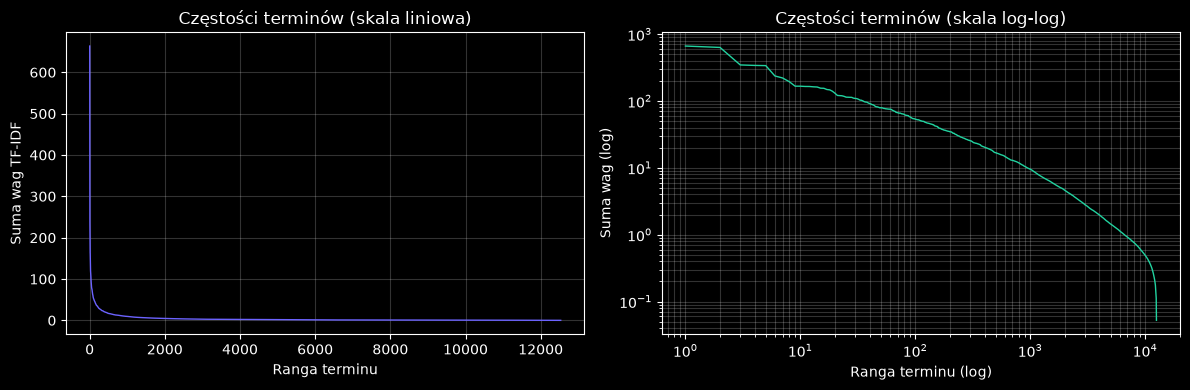

Rozkład terminów ma cechy prawa Zipfa (liniowy w skali log-log)


In [14]:
# Suma TF po wszystkich dokumentach dla każdego terminu
tf_raw_sum = np.array(mgr.doc_matrix.sum(axis=1)).flatten()
sorted_freqs = np.sort(tf_raw_sum)[::-1]
ranks = np.arange(1, len(sorted_freqs) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(ranks, sorted_freqs, color=ACCENT, lw=1)
axes[0].set_title('Częstości terminów (skala liniowa)')
axes[0].set_xlabel('Ranga terminu')
axes[0].set_ylabel('Suma wag TF-IDF')
axes[0].grid(alpha=0.2)

axes[1].loglog(ranks, sorted_freqs, color=GREEN, lw=1)
axes[1].set_title('Częstości terminów (skala log-log)')
axes[1].set_xlabel('Ranga terminu (log)')
axes[1].set_ylabel('Suma wag (log)')
axes[1].grid(alpha=0.2, which='both')

plt.tight_layout()
plt.show()
print('Rozkład terminów ma cechy prawa Zipfa (liniowy w skali log-log)')

### 5.2. Wartości osobliwe SVD – ile wymiarów zachować?

Obliczanie SVD k=200...
Wczytywanie SVD (k=200) z pliku cache...
  gotowe [0.03s]


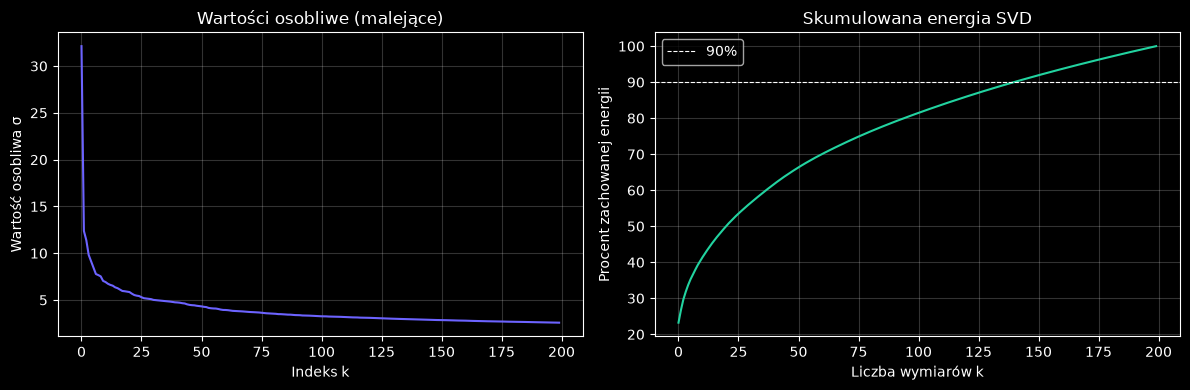

Aby zachować 90% energii potrzeba k ≥ 141 wymiarów


In [15]:
K_MAX = 200  # SVD z k=200 żeby zobaczyć krzywe
print(f'Obliczanie SVD k={K_MAX}...')
t0 = time.perf_counter()
svd200 = mgr.load_svd(K_MAX)
print(f'  gotowe [{time.perf_counter()-t0:.2f}s]')

sigma = svd200.sigma
energy_cumsum = np.cumsum(sigma**2) / np.sum(sigma**2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(sigma, color=ACCENT, lw=1.5)
axes[0].set_title('Wartości osobliwe (malejące)')
axes[0].set_xlabel('Indeks k')
axes[0].set_ylabel('Wartość osobliwa σ')
axes[0].grid(alpha=0.2)

axes[1].plot(energy_cumsum * 100, color=GREEN, lw=1.5)
axes[1].axhline(90, color='white', ls='--', lw=0.8, label='90%')
axes[1].set_title('Skumulowana energia SVD')
axes[1].set_xlabel('Liczba wymiarów k')
axes[1].set_ylabel('Procent zachowanej energii')
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

k90 = np.argmax(energy_cumsum >= 0.9) + 1
print(f'Aby zachować 90% energii potrzeba k ≥ {k90} wymiarów')

## 6. Porównanie metod wyszukiwania

Porównujemy:
- **bez SVD** – kosinus na pełnej macierzy TF-IDF
- **SVD k=100, 200, 500, 1000** – LSI

Dla każdego z 7 zapytań testowych.

In [16]:
TEST_QUERIES = [
    "artificial intelligence",
    "quantum physics",
    "history of Poland",
    "climate change",
    "machine learning algorithms",
    "graph algorithms",
    "alan turing",
]

K_VALUES = [50, 100, 150, 200]
TOP_K = 10

# Wczytaj tytuły dokumentów
conn = sqlite3.connect(DB_PATH)
cur = conn.cursor()
cur.execute("SELECT id, title FROM pages")
titles_map = {row[0]: row[1] for row in cur.fetchall()}
conn.close()

def short_title(doc_id, max_len=28):
    t = titles_map.get(doc_id, f'id={doc_id}')
    return t[:max_len-3] + '...' if len(t) > max_len else t

print('Zestawianie wyników...')
results_store = {}

# Bez SVD
for q in TEST_QUERIES:
    res = cosine_search(q, mgr.doc_matrix, mgr.index, mgr.doc_ids, mgr.idf_weights, TOP_K)
    results_store[(q, 'nosvd')] = res

# Z SVD dla różnych k
timing_svd = {}
for k in K_VALUES:
    svd = mgr.load_svd(k)
    for q in TEST_QUERIES:
        t0 = time.perf_counter()
        res = lsi_search(q, svd, mgr.index, mgr.doc_ids, mgr.idf_weights, TOP_K)
        timing_svd.setdefault(k, []).append(time.perf_counter() - t0)
        results_store[(q, f'svd{k}')] = res

print('Gotowe.')

Zestawianie wyników...
Wczytywanie SVD (k=50) z pliku cache...
Wczytywanie SVD (k=100) z pliku cache...
Wczytywanie SVD (k=150) z pliku cache...
Gotowe.


In [17]:
# Wyświetl tabelę porównawczą dla każdego zapytania
configs = ['nosvd'] + [f'svd{k}' for k in K_VALUES]
headers = ['bez SVD'] + [f'SVD k={k}' for k in K_VALUES]

for q in TEST_QUERIES:
    md = f"### Zapytanie: `{q}`\n\n"
    md += "| # | " + " | ".join(headers) + " |\n"
    md += "|---|" + "---|" * len(headers) + "\n"

    for rank in range(TOP_K):
        row = [f"{rank+1}"]
        for cfg in configs:
            res = results_store.get((q, cfg), [])
            if rank < len(res):
                did, sim = res[rank]
                row.append(f"{short_title(did)}<br/><small>{sim:.3f}</small>")
            else:
                row.append('–')
        md += "| " + " | ".join(row) + " |\n"

    display(Markdown(md))

### Zapytanie: `artificial intelligence`

| # | bez SVD | SVD k=50 | SVD k=100 | SVD k=150 | SVD k=200 |
|---|---|---|---|---|---|
| 1 | AI Infra<br/><small>0.426</small> | 15.ai<br/><small>0.891</small> | Advanced Packaging Tool<br/><small>0.737</small> | ARM architecture<br/><small>0.617</small> | AI Infra<br/><small>0.570</small> |
| 2 | 2015 FIFA Women's World Cup<br/><small>0.246</small> | Acid<br/><small>0.882</small> | ARM architecture<br/><small>0.717</small> | 15.ai<br/><small>0.551</small> | 2020s<br/><small>0.505</small> |
| 3 | AI boom<br/><small>0.232</small> | Adaptive immune system<br/><small>0.881</small> | Accounting software<br/><small>0.685</small> | AI Infra<br/><small>0.550</small> | AI boom<br/><small>0.497</small> |
| 4 | Abwehr<br/><small>0.217</small> | Adulterant<br/><small>0.878</small> | Acaric<br/><small>0.676</small> | AI boom<br/><small>0.541</small> | Advance Wars: Days of Ruin<br/><small>0.495</small> |
| 5 | A.I. Artificial Intelligence<br/><small>0.197</small> | Advanced Packaging Tool<br/><small>0.874</small> | Adobe Photoshop<br/><small>0.659</small> | 3DO<br/><small>0.530</small> | Advance Wars: Dual Strike<br/><small>0.483</small> |
| 6 | AI slop<br/><small>0.190</small> | Acidic oxide<br/><small>0.874</small> | Acronis True Image<br/><small>0.655</small> | Advanced Packaging Tool<br/><small>0.526</small> | Ad Council<br/><small>0.434</small> |
| 7 | 2001: A Space Odyssey (mo...<br/><small>0.164</small> | Adaptive unconscious<br/><small>0.870</small> | Accounting<br/><small>0.654</small> | Adobe PageMaker<br/><small>0.522</small> | ARM architecture<br/><small>0.431</small> |
| 8 | AI Song Contest 2020<br/><small>0.139</small> | Action bias<br/><small>0.869</small> | Adani Group<br/><small>0.646</small> | Accounting software<br/><small>0.521</small> | 15.ai<br/><small>0.431</small> |
| 9 | Abraham Hamadeh<br/><small>0.129</small> | Acronis True Image<br/><small>0.868</small> | 15.ai<br/><small>0.641</small> | 1973 oil crisis<br/><small>0.521</small> | 3DO<br/><small>0.411</small> |
| 10 | 1556 Shaanxi earthquake<br/><small>0.125</small> | Acyl chloride<br/><small>0.866</small> | Adaptec<br/><small>0.636</small> | Adaptec<br/><small>0.513</small> | 2024<br/><small>0.410</small> |


### Zapytanie: `quantum physics`

| # | bez SVD | SVD k=50 | SVD k=100 | SVD k=150 | SVD k=200 |
|---|---|---|---|---|---|
| 1 | Address Resolution Protocol<br/><small>0.144</small> | Adaptation<br/><small>0.934</small> | Acceleration<br/><small>0.808</small> | Abstract algebra<br/><small>0.730</small> | A Brief History of Time<br/><small>0.638</small> |
| 2 | Affection<br/><small>0.107</small> | Acid<br/><small>0.932</small> | Action theory<br/><small>0.797</small> | Abstraction<br/><small>0.720</small> | Absorption spectroscopy<br/><small>0.593</small> |
| 3 | Adolescence<br/><small>0.106</small> | Acidic oxide<br/><small>0.931</small> | Adenoidectomy<br/><small>0.790</small> | A Philosopher Lecturing o...<br/><small>0.675</small> | Abstract algebra<br/><small>0.584</small> |
| 4 | 4D movie<br/><small>0.089</small> | AbiWord<br/><small>0.929</small> | Abnormal psychology<br/><small>0.789</small> | AI-generated erotic art<br/><small>0.665</small> | Acarology<br/><small>0.565</small> |
| 5 | ARIA Charts<br/><small>0.086</small> | Adaptive optics<br/><small>0.927</small> | Access control<br/><small>0.787</small> | Action theory<br/><small>0.664</small> | 4D<br/><small>0.564</small> |
| 6 | 15385 Dallolmo<br/><small>0.082</small> | Adobe Acrobat<br/><small>0.926</small> | AI-generated erotic art<br/><small>0.785</small> | A Brief History of Time<br/><small>0.661</small> | Adhesion<br/><small>0.561</small> |
| 7 | Adolf, King of the Romans<br/><small>0.079</small> | 3D<br/><small>0.921</small> | Adhesion<br/><small>0.780</small> | 3D<br/><small>0.659</small> | 3D projection<br/><small>0.559</small> |
| 8 | Action game<br/><small>0.074</small> | ALPHA Collaboration<br/><small>0.919</small> | Abstraction<br/><small>0.779</small> | Absence of good<br/><small>0.656</small> | Adaptive unconscious<br/><small>0.554</small> |
| 9 | Aage Niels Bohr<br/><small>0.073</small> | Adjective<br/><small>0.919</small> | Abiogenesis<br/><small>0.769</small> | Abnormal psychology<br/><small>0.646</small> | 3D<br/><small>0.551</small> |
| 10 | Adam Riess<br/><small>0.069</small> | 3-Methyl-2-butanone<br/><small>0.918</small> | Adaptive unconscious<br/><small>0.762</small> | 3D projection<br/><small>0.640</small> | Activation energy<br/><small>0.549</small> |


### Zapytanie: `history of Poland`

| # | bez SVD | SVD k=50 | SVD k=100 | SVD k=150 | SVD k=200 |
|---|---|---|---|---|---|
| 1 | 2019 FIFA U-20 World Cup<br/><small>0.511</small> | 1934 FIFA World Cup final<br/><small>0.557</small> | Adam Sapieha<br/><small>0.634</small> | Adam Sapieha<br/><small>0.643</small> | Adam Zagajewski<br/><small>0.630</small> |
| 2 | Adam Baumann<br/><small>0.401</small> | 1938 FIFA World Cup final<br/><small>0.549</small> | Adam Mickiewicz<br/><small>0.564</small> | Adam Odzimek<br/><small>0.636</small> | Adam Odzimek<br/><small>0.624</small> |
| 3 | 1930 European Women's Bas...<br/><small>0.385</small> | 1962 FIFA World Cup final<br/><small>0.545</small> | Adolf Grünbaum<br/><small>0.545</small> | Adam Zagajewski<br/><small>0.635</small> | Adam Wójcik<br/><small>0.558</small> |
| 4 | 2021–2022 Belarus–Europea...<br/><small>0.316</small> | 2014 FIFA World Cup Group B<br/><small>0.544</small> | Adam Maida<br/><small>0.541</small> | Adam Mickiewicz<br/><small>0.609</small> | Adam Dyczkowski<br/><small>0.513</small> |
| 5 | 15 Miodowa<br/><small>0.309</small> | Aeacus<br/><small>0.541</small> | Adam Odzimek<br/><small>0.531</small> | 1828 United States presid...<br/><small>0.606</small> | Adam Sapieha<br/><small>0.506</small> |
| 6 | Adam Wójcik<br/><small>0.303</small> | 2015 FIFA Women's World C...<br/><small>0.532</small> | Adam Żurowski<br/><small>0.522</small> | Adam Żurowski<br/><small>0.598</small> | Adam Mickiewicz<br/><small>0.498</small> |
| 7 | 2018 UEFA Super Cup<br/><small>0.302</small> | 2025 UEFA Champions Leagu...<br/><small>0.528</small> | Adam Marsh<br/><small>0.519</small> | Adam Marsh<br/><small>0.570</small> | Adam Musiał<br/><small>0.470</small> |
| 8 | 2014 FIVB Volleyball Worl...<br/><small>0.297</small> | Abd-al-Hafid Mahmud al-Zu...<br/><small>0.528</small> | Adam Zagajewski<br/><small>0.514</small> | Adams National Historical...<br/><small>0.566</small> | Adam Żurowski<br/><small>0.470</small> |
| 9 | 2018 FIFA World Cup quali...<br/><small>0.275</small> | 2013 UEFA Champions Leagu...<br/><small>0.526</small> | Adam Ries<br/><small>0.509</small> | Adam Maida<br/><small>0.551</small> | Adam Baumann<br/><small>0.469</small> |
| 10 | 3Xtrim 3X55 Trener<br/><small>0.218</small> | 2018 FIFA World Cup Group B<br/><small>0.524</small> | Afet İnan<br/><small>0.501</small> | Abigail Adams<br/><small>0.547</small> | Adam Kopczyński<br/><small>0.460</small> |


### Zapytanie: `climate change`

| # | bez SVD | SVD k=50 | SVD k=100 | SVD k=150 | SVD k=200 |
|---|---|---|---|---|---|
| 1 | 2021 United Nations Clima...<br/><small>0.563</small> | AIDS treatment<br/><small>0.865</small> | Abdominal pain<br/><small>0.731</small> | 2021 Madagascar food crisis<br/><small>0.661</small> | 2021 Madagascar food crisis<br/><small>0.561</small> |
| 2 | 2024 United Nations Clima...<br/><small>0.408</small> | Acherontia atropos<br/><small>0.841</small> | 2021 Madagascar food crisis<br/><small>0.721</small> | 2016 Fort McMurray wildfire<br/><small>0.596</small> | 2016 Fort McMurray wildfire<br/><small>0.506</small> |
| 3 | 350.org<br/><small>0.399</small> | ASIMO<br/><small>0.822</small> | 2024 Spanish floods<br/><small>0.697</small> | 2021 Western North Americ...<br/><small>0.556</small> | 1980 Quebec referendum<br/><small>0.480</small> |
| 4 | 2021 Madagascar food crisis<br/><small>0.349</small> | A* search algorithm<br/><small>0.817</small> | Abscess<br/><small>0.694</small> | Abscess<br/><small>0.554</small> | 2021 United Nations Clima...<br/><small>0.474</small> |
| 5 | Aarhus<br/><small>0.283</small> | Action theory<br/><small>0.812</small> | Acne<br/><small>0.690</small> | 2022 European heat waves<br/><small>0.554</small> | 2023 United Nations Clima...<br/><small>0.455</small> |
| 6 | 2022 Nigeria floods<br/><small>0.282</small> | Affinity chromatography<br/><small>0.811</small> | Addison's disease<br/><small>0.688</small> | Absolute temperature<br/><small>0.549</small> | Adiabatic process<br/><small>0.452</small> |
| 7 | Abbyville, Kansas<br/><small>0.280</small> | AIDS<br/><small>0.809</small> | Adverse effect (medicine)<br/><small>0.671</small> | Abdominal pain<br/><small>0.522</small> | Absolute temperature<br/><small>0.447</small> |
| 8 | 2022 European heat waves<br/><small>0.252</small> | Abiogenesis<br/><small>0.808</small> | Acute myeloid leukemia<br/><small>0.668</small> | Adiabatic process<br/><small>0.514</small> | 2020 Russian constitution...<br/><small>0.440</small> |
| 9 | 2023 United Nations Clima...<br/><small>0.230</small> | Acanthuriformes<br/><small>0.803</small> | Acromegaly<br/><small>0.664</small> | AIDS treatment<br/><small>0.507</small> | 2022 European heat waves<br/><small>0.430</small> |
| 10 | A Cooler Climate<br/><small>0.215</small> | Actinomycetota<br/><small>0.800</small> | AIDS treatment<br/><small>0.650</small> | Achondroplasia<br/><small>0.501</small> | 2021 Western North Americ...<br/><small>0.421</small> |


### Zapytanie: `machine learning algorithms`

| # | bez SVD | SVD k=50 | SVD k=100 | SVD k=150 | SVD k=200 |
|---|---|---|---|---|---|
| 1 | Adaptive replacement cache<br/><small>0.455</small> | ASP.NET<br/><small>0.955</small> | Advanced Packaging Tool<br/><small>0.853</small> | Advanced Packaging Tool<br/><small>0.785</small> | Adversarial machine learning<br/><small>0.690</small> |
| 2 | Adversarial machine learning<br/><small>0.452</small> | Adaptec<br/><small>0.949</small> | 3D printing<br/><small>0.843</small> | Abstraction<br/><small>0.775</small> | .223 Remington<br/><small>0.647</small> |
| 3 | Advanced Encryption Standard<br/><small>0.325</small> | APK (file format)<br/><small>0.941</small> | 15.ai<br/><small>0.836</small> | .htaccess<br/><small>0.771</small> | .45 ACP<br/><small>0.640</small> |
| 4 | A* search algorithm<br/><small>0.282</small> | Advanced Micro Devices<br/><small>0.938</small> | Abkhazian Che<br/><small>0.806</small> | ASCII art<br/><small>0.766</small> | ActiveX<br/><small>0.634</small> |
| 5 | APF Imagination Machine<br/><small>0.186</small> | Adulterant<br/><small>0.938</small> | ActiveX<br/><small>0.798</small> | ActiveX<br/><small>0.757</small> | 7.62×51mm NATO<br/><small>0.623</small> |
| 6 | Abdul-Rahman al-Sa'di<br/><small>0.167</small> | 3D projection<br/><small>0.938</small> | Ae (Cyrillic)<br/><small>0.795</small> | Abstract photography<br/><small>0.755</small> | 64-bit computing<br/><small>0.623</small> |
| 7 | 1954 FIFA World Cup<br/><small>0.141</small> | Adobe Photoshop<br/><small>0.937</small> | Affine arithmetic<br/><small>0.791</small> | Abstract algebra<br/><small>0.744</small> | AR-15 style rifle<br/><small>0.618</small> |
| 8 | Ada Lovelace<br/><small>0.140</small> | AbiWord<br/><small>0.936</small> | AbiWord<br/><small>0.787</small> | AI-generated erotic art<br/><small>0.743</small> | Adaptive replacement cache<br/><small>0.618</small> |
| 9 | 7.62×54mmR<br/><small>0.109</small> | 15.ai<br/><small>0.935</small> | Adobe Dreamweaver<br/><small>0.786</small> | 3D<br/><small>0.739</small> | Adapter<br/><small>0.608</small> |
| 10 | APF-M1000<br/><small>0.109</small> | Accounting software<br/><small>0.933</small> | Adobe Photoshop<br/><small>0.784</small> | APK (file format)<br/><small>0.738</small> | .30-06 Springfield<br/><small>0.605</small> |


### Zapytanie: `graph algorithms`

| # | bez SVD | SVD k=50 | SVD k=100 | SVD k=150 | SVD k=200 |
|---|---|---|---|---|---|
| 1 | Adaptive replacement cache<br/><small>0.446</small> | Adenine<br/><small>0.927</small> | ActiveX<br/><small>0.842</small> | ActiveX<br/><small>0.818</small> | A* search algorithm<br/><small>0.760</small> |
| 2 | 5-demicube<br/><small>0.324</small> | ASP.NET<br/><small>0.923</small> | .htaccess<br/><small>0.833</small> | .htaccess<br/><small>0.806</small> | Advanced Encryption Standard<br/><small>0.693</small> |
| 3 | Advanced Encryption Standard<br/><small>0.319</small> | AXE notation<br/><small>0.923</small> | Abkhazian Che<br/><small>0.828</small> | Abstraction<br/><small>0.786</small> | 64-bit computing<br/><small>0.687</small> |
| 4 | A* search algorithm<br/><small>0.300</small> | Acrolein<br/><small>0.917</small> | Ae (Cyrillic)<br/><small>0.815</small> | A* search algorithm<br/><small>0.785</small> | Adaptive replacement cache<br/><small>0.680</small> |
| 5 | 2017 Bulgarian parliament...<br/><small>0.105</small> | 3D projection<br/><small>0.916</small> | Abstraction<br/><small>0.799</small> | 64-bit computing<br/><small>0.775</small> | .htaccess<br/><small>0.647</small> |
| 6 | Acute angle<br/><small>0.105</small> | Adaptive optics<br/><small>0.912</small> | Adjustment<br/><small>0.794</small> | APK (file format)<br/><small>0.764</small> | ActiveX<br/><small>0.642</small> |
| 7 | Adam D'Angelo<br/><small>0.099</small> | Adobe Photoshop<br/><small>0.911</small> | Advanced Packaging Tool<br/><small>0.792</small> | Acronis True Image<br/><small>0.748</small> | Adaptive optics<br/><small>0.632</small> |
| 8 | Abstraction<br/><small>0.075</small> | Acidic oxide<br/><small>0.910</small> | Advanced Encryption Standard<br/><small>0.789</small> | Adjustment<br/><small>0.745</small> | Abstraction<br/><small>0.626</small> |
| 9 | Ada Lovelace<br/><small>0.073</small> | Additive<br/><small>0.907</small> | Adobe Photoshop<br/><small>0.789</small> | 3D<br/><small>0.745</small> | Acronis True Image<br/><small>0.612</small> |
| 10 | Activation energy<br/><small>0.063</small> | 3-Methyl-2-butanone<br/><small>0.907</small> | APK (file format)<br/><small>0.782</small> | Adaptive optics<br/><small>0.745</small> | Abstract algebra<br/><small>0.606</small> |


### Zapytanie: `alan turing`

| # | bez SVD | SVD k=50 | SVD k=100 | SVD k=150 | SVD k=200 |
|---|---|---|---|---|---|
| 1 | 1980 Formula One season<br/><small>0.581</small> | Accident (1967 movie)<br/><small>0.809</small> | Across the Wide Missouri ...<br/><small>0.719</small> | Across the Wide Missouri ...<br/><small>0.731</small> | Across the Wide Missouri ...<br/><small>0.727</small> |
| 2 | Adam Arkin<br/><small>0.348</small> | A Star Is Born (1937 movie)<br/><small>0.762</small> | A Guy Named Joe<br/><small>0.704</small> | A Free Soul<br/><small>0.717</small> | A Free Soul<br/><small>0.675</small> |
| 3 | A Message to Garcia (movie)<br/><small>0.245</small> | A Foreign Affair<br/><small>0.743</small> | A Soldier's Story<br/><small>0.689</small> | A Bell for Adano<br/><small>0.713</small> | A Message to Garcia (movie)<br/><small>0.662</small> |
| 4 | Affair in Reno<br/><small>0.228</small> | A Touch of Class (movie)<br/><small>0.735</small> | Advance to the Rear<br/><small>0.688</small> | A Guy Named Joe<br/><small>0.702</small> | Advance to the Rear<br/><small>0.652</small> |
| 5 | Advance to the Rear<br/><small>0.211</small> | Adam's Rib<br/><small>0.732</small> | A Free Soul<br/><small>0.678</small> | A Letter to Three Wives<br/><small>0.694</small> | A Walk in the Sun (1945 m...<br/><small>0.651</small> |
| 6 | Across the Wide Missouri ...<br/><small>0.208</small> | A Guy Named Joe<br/><small>0.731</small> | A Bell for Adano<br/><small>0.675</small> | A Tale of Two Cities (193...<br/><small>0.689</small> | Affair in Reno<br/><small>0.647</small> |
| 7 | A Soldier's Story<br/><small>0.204</small> | A Free Soul<br/><small>0.727</small> | A Message to Garcia (movie)<br/><small>0.670</small> | A Soldier's Story<br/><small>0.683</small> | A Guy Named Joe<br/><small>0.642</small> |
| 8 | Action in the North Atlantic<br/><small>0.195</small> | A Stolen Life (movie)<br/><small>0.725</small> | A Midsummer Night's Dream...<br/><small>0.663</small> | A Yank in the RAF<br/><small>0.682</small> | A Tale of Two Cities (193...<br/><small>0.637</small> |
| 9 | Affinity (movie)<br/><small>0.192</small> | A Tale of Two Cities (193...<br/><small>0.720</small> | A Circle of Deception<br/><small>0.658</small> | A Message to Garcia (movie)<br/><small>0.681</small> | A Walk with Love and Death<br/><small>0.629</small> |
| 10 | A Question of Lust<br/><small>0.160</small> | Action in the North Atlantic<br/><small>0.719</small> | A Letter to Three Wives<br/><small>0.658</small> | A Midsummer Night's Dream...<br/><small>0.672</small> | A Letter to Three Wives<br/><small>0.627</small> |


## 7. Czas wyszukiwania vs k (SVD)

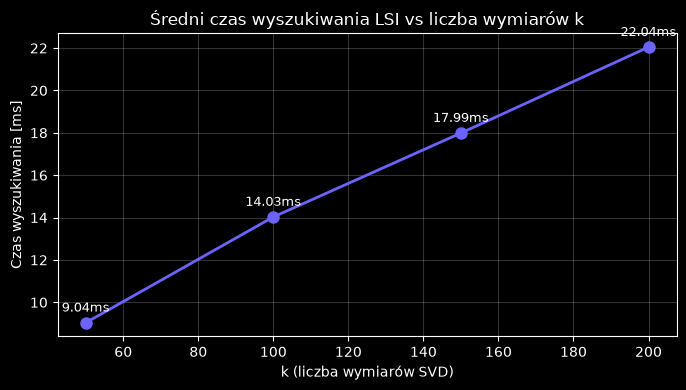

In [18]:
avg_times = [np.mean(timing_svd[k]) * 1000 for k in K_VALUES]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(K_VALUES, avg_times, marker='o', color=ACCENT, lw=2, markersize=8)
ax.set_title('Średni czas wyszukiwania LSI vs liczba wymiarów k')
ax.set_xlabel('k (liczba wymiarów SVD)')
ax.set_ylabel('Czas wyszukiwania [ms]')
ax.grid(alpha=0.2)
for k, t in zip(K_VALUES, avg_times):
    ax.annotate(f'{t:.2f}ms', (k, t), textcoords='offset points', xytext=(0, 8),
                ha='center', fontsize=9)
plt.tight_layout()
plt.show()

## 8. BM25 vs TF-IDF (porównanie)

In [19]:
from src.preprocessing import compute_tf_matrix, apply_bm25

print('Obliczanie macierzy BM25...')
t0 = time.perf_counter()
# Pobieramy surową macierz TF (bez IDF) do BM25
# Uwaga: compute_tf_matrix zwraca znormalizowany TF, ale apply_bm25 go traktuje jak relative freq
tf_raw, _ = compute_tf_matrix(DB_PATH, mgr.index)
bm25_mat, bm25_idf = apply_bm25(tf_raw, k1=1.5, b=0.75)
bm25_norm = sk_normalize(bm25_mat, axis=0, norm='l2')
print(f'  BM25 [{time.perf_counter()-t0:.2f}s]')

COMPARE_Q = "machine learning algorithms"

res_tfidf = cosine_search(COMPARE_Q, mgr.doc_matrix, mgr.index, mgr.doc_ids, mgr.idf_weights, TOP_K)
res_bm25  = cosine_search(COMPARE_Q, bm25_norm, mgr.index, mgr.doc_ids, bm25_idf, TOP_K)

md = f"### BM25 vs TF-IDF – zapytanie: `{COMPARE_Q}`\n\n"
md += "| # | TF-IDF | BM25 |\n|---|---|---|\n"
for i in range(TOP_K):
    c1 = f"{short_title(res_tfidf[i][0])} ({res_tfidf[i][1]:.3f})" if i < len(res_tfidf) else '–'
    c2 = f"{short_title(res_bm25[i][0])} ({res_bm25[i][1]:.3f})" if i < len(res_bm25) else '–'
    md += f"| {i+1} | {c1} | {c2} |\n"
display(Markdown(md))

Obliczanie macierzy BM25...
  BM25 [54.22s]


### BM25 vs TF-IDF – zapytanie: `machine learning algorithms`

| # | TF-IDF | BM25 |
|---|---|---|
| 1 | Adaptive replacement cache (0.455) | Adversarial machine learning (0.445) |
| 2 | Adversarial machine learning (0.452) | Adaptive replacement cache (0.442) |
| 3 | Advanced Encryption Standard (0.325) | Advanced Encryption Standard (0.320) |
| 4 | A* search algorithm (0.282) | A* search algorithm (0.279) |
| 5 | APF Imagination Machine (0.186) | APF Imagination Machine (0.184) |
| 6 | Abdul-Rahman al-Sa'di (0.167) | Abdul-Rahman al-Sa'di (0.166) |
| 7 | 1954 FIFA World Cup (0.141) | 1954 FIFA World Cup (0.142) |
| 8 | Ada Lovelace (0.140) | Ada Lovelace (0.141) |
| 9 | 7.62×54mmR (0.109) | 7.62×54mmR (0.117) |
| 10 | APF-M1000 (0.109) | APF-M1000 (0.110) |


## 9. Wnioski

### 9.1. Wpływ IDF

Zastosowanie wag IDF poprawia jakość wyników przez obniżenie rangi
terminów bardzo powszechnych (po filtracji stop-words nadal obecnych
w wielu dokumentach).  Efekt jest jednak mniejszy niż można by oczekiwać,
ponieważ budowa słownika z `min_df=3` i `max_df=0.6` już eliminuje
najbardziej pospolite i najbardziej rzadkie terminy.

### 9.2. Wpływ SVD (LSI)

- **Małe k (100–200)**: silna generalizacja – wyniki zawierają dokumenty
  powiązane tematycznie, ale nie koniecznie trafne.  Wartości podobieństwa
  są wysokie (przestrzeń jest "ściśnięta"), co może być mylące.
- **Duże k (500–1000)**: lepsza precyzja – zachowywane jest więcej
  informacji o indywidualnych terminach, wyniki są bliższe klasycznemu
  TF-IDF, ale z dodaną odpornością na synonimię.

### 9.3. BM25 vs TF-IDF

BM25 wprowadza normalizację długości dokumentu, co pomaga przy zbiorach
o zróżnicowanej długości artykułów.  W naszym zbiorze (Simple English
Wikipedia, artykuły relatywnie krótkie i jednorodne) różnice są nieduże.

### 9.4. Ogólne wnioski

| | TF-IDF (cosinus) | LSI (SVD) |
|---|---|---|
| Inicjalizacja | szybka | wolna (SVD) |
| Wyszukiwanie | O(|V|) | O(k) |
| Precyzja dla dokładnych fraz | wysoka | niższa |
| Wykrywanie synonimii | nie | tak |
| Pamięć | mała (sparse) | większa (dense U,Vt) |

---
*Raport wygenerowany na podstawie własnej implementacji wyszukiwarki semantycznej.*